<a href="https://colab.research.google.com/github/carolinaaraujo-cap/C-lculo-Num-rico/blob/main/Atividade_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Importa a biblioteca de funções matemáticas da linguagem Python.
import math

# Importa a biblioteca NumPy e cria o apelido convencional np.
import numpy as np

# Importa o módulo de gráficos pyplot e cria o apelido plt.
import matplotlib.pyplot as plt

# Define um estilo visual claro para todos os gráficos do notebook.
plt.style.use("seaborn-v0_8-whitegrid")

Se x é o valor de referência e x ̃︁ é uma aproximação, use

Ea = |x − x ̃︁| erro absoluto, (1)
Er =
|x − x ̃︁|
|x|

erro relativo, (2)
E% = 100Er erro percentual. (3)

Para n casas decimais:
• arredondamento: considera o primeiro algarismo descartado;
• truncamento: simplesmente elimina os algarismos posteriores à casa escolhida.
No Python, round(x,n) pode ser usado para arredondar. Para truncar sem arredondar,
implemente

xtrunc =
trunc(10nx)
10n
.


Valor original de x1: 3.14159265

Para 0 casas decimais:
  Arredondado: 3.0
    Erro absoluto:   0.1415926500
    Erro relativo:   4.507034e-02
    Erro percentual: 4.507034%
  Truncado: 3.0
    Erro absoluto:   0.1415926500
    Erro relativo:   4.507034e-02
    Erro percentual: 4.507034%

Para 1 casas decimais:
  Arredondado: 3.1
    Erro absoluto:   0.0415926500
    Erro relativo:   1.323935e-02
    Erro percentual: 1.323935%
  Truncado: 3.1
    Erro absoluto:   0.0415926500
    Erro relativo:   1.323935e-02
    Erro percentual: 1.323935%

Para 2 casas decimais:
  Arredondado: 3.14
    Erro absoluto:   0.0015926500
    Erro relativo:   5.069562e-04
    Erro percentual: 0.050696%
  Truncado: 3.14
    Erro absoluto:   0.0015926500
    Erro relativo:   5.069562e-04
    Erro percentual: 0.050696%

Para 3 casas decimais:
  Arredondado: 3.142
    Erro absoluto:   0.0004073500
    Erro relativo:   1.296635e-04
    Erro percentual: 0.012966%
  Truncado: 3.141
    Erro absoluto:   0.00059265

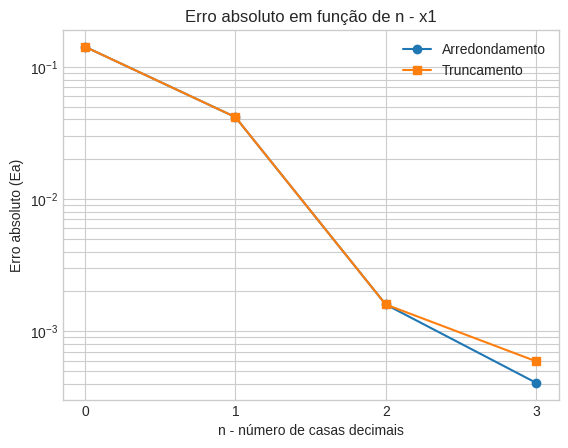

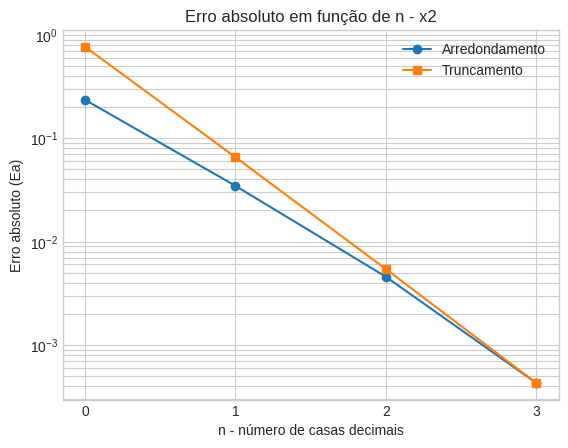

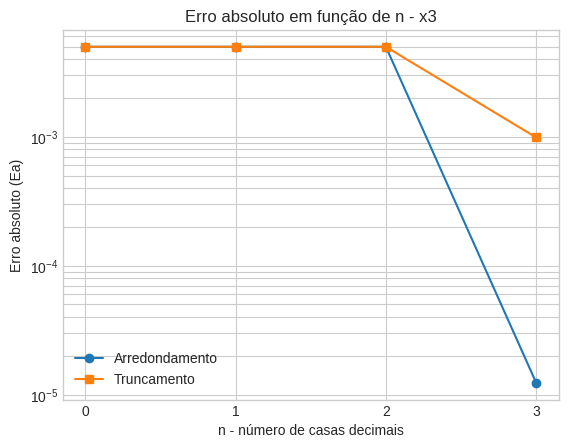

In [5]:
import math
import pandas as pd
import matplotlib.pyplot as plt


# Valores de referência
x1 = 3.14159265
x2 = 98.76543
x3 = 0.00498765


# ==========================================================
# FUNÇÃO PARA TRUNCAMENTO
# ==========================================================

# Define a função para truncar um número em determinada
# quantidade de casas decimais.
def truncar(value, num_decimals):

    # Calcula o fator que desloca a vírgula decimal.
    fator = 10 ** num_decimals

    # Trunca o número deslocado e devolve a vírgula
    # à posição original.
    return math.trunc(value * fator) / fator


# ==========================================================
# FUNÇÃO PARA CÁLCULO DOS ERROS
# ==========================================================

def calcular_erros(valor_referencia, valor_aproximado):

    # Calcula a distância entre o valor de referência
    # e a aproximação.
    erro_absoluto = abs(valor_referencia - valor_aproximado)

    # Divide o erro absoluto pelo módulo do valor de referência.
    erro_relativo = erro_absoluto / abs(valor_referencia)

    # Converte o erro relativo em porcentagem.
    erro_percentual = 100.0 * erro_relativo

    return erro_absoluto, erro_relativo, erro_percentual


# ==========================================================
# VALORES QUE SERÃO PROCESSADOS
# ==========================================================

numbers_to_process = {
    "x1": x1,
    "x2": x2,
    "x3": x3
}


# Lista para armazenar os resultados
resultados = []


# ==========================================================
# ARREDONDAMENTO E TRUNCAMENTO
# ==========================================================

for name, value in numbers_to_process.items():

    print(f"\nValor original de {name}: {value}")

    for n in range(0, 4):

        print(f"\nPara {n} casas decimais:")


        # --------------------------------------------------
        # ARREDONDAMENTO
        # --------------------------------------------------

        arredondado = round(value, n)

        Ea, Er, Epercentual = calcular_erros(
            value,
            arredondado
        )

        print(f"  Arredondado: {arredondado}")

        # Exibe o erro absoluto com dez casas decimais.
        print(f"    Erro absoluto:   {Ea:.10f}")

        # Exibe o erro relativo em notação científica.
        print(f"    Erro relativo:   {Er:.6e}")

        # Exibe o erro percentual com seis casas decimais.
        print(f"    Erro percentual: {Epercentual:.6f}%")

        resultados.append([
            name,
            value,
            n,
            "Arredondamento",
            arredondado,
            Ea,
            Er,
            Epercentual
        ])


        # --------------------------------------------------
        # TRUNCAMENTO
        # --------------------------------------------------

        truncado = truncar(value, n)

        Ea, Er, Epercentual = calcular_erros(
            value,
            truncado
        )

        print(f"  Truncado: {truncado}")

        # Exibe o erro absoluto com dez casas decimais.
        print(f"    Erro absoluto:   {Ea:.10f}")

        # Exibe o erro relativo em notação científica.
        print(f"    Erro relativo:   {Er:.6e}")

        # Exibe o erro percentual com seis casas decimais.
        print(f"    Erro percentual: {Epercentual:.6f}%")

        resultados.append([
            name,
            value,
            n,
            "Truncamento",
            truncado,
            Ea,
            Er,
            Epercentual
        ])


# ==========================================================
# 3. ORGANIZA OS RESULTADOS EM UMA TABELA
# ==========================================================

tabela = pd.DataFrame(
    resultados,
    columns=[
        "Número",
        "Valor de referência",
        "n",
        "Método",
        "Valor aproximado",
        "Ea",
        "Er",
        "E%"
    ]
)

print("\n")
print("=" * 80)
print("TABELA DE RESULTADOS")
print("=" * 80)

print(tabela.to_string(index=False))


# ==========================================================
# 4. GRÁFICO DE Ea EM FUNÇÃO DE n
# ==========================================================

for name in numbers_to_process:

    # Seleciona apenas os dados do número atual
    dados = tabela[tabela["Número"] == name]

    # Separa arredondamento e truncamento
    arred = dados[dados["Método"] == "Arredondamento"]
    trunc = dados[dados["Método"] == "Truncamento"]


    # Cria uma nova figura
    plt.figure()


    # Erro do arredondamento
    plt.semilogy(
        arred["n"],
        arred["Ea"],
        marker="o",
        label="Arredondamento"
    )


    # Erro do truncamento
    plt.semilogy(
        trunc["n"],
        trunc["Ea"],
        marker="s",
        label="Truncamento"
    )


    # Nome dos eixos
    plt.xlabel("n - número de casas decimais")
    plt.ylabel("Erro absoluto (Ea)")


    # Título
    plt.title(
        f"Erro absoluto em função de n - {name}"
    )


    # Define os valores mostrados no eixo x
    plt.xticks(range(0, 4))


    # Grade
    plt.grid(
        True,
        which="both"
    )


    # Legenda
    plt.legend()


    # Mostra o gráfico
    plt.show()

**5. responda: arredondar sempre gera erro menor ou igual ao truncamento? Justifique com os resultados.**
Como demonstram os resultados acima, a técnica de arredondamento geraram erros menore ou iguais aos do truncamento, isto porque leva em consideração a casa decimal seguinte.

Parte B – medidas de pressão arterial
Um equipamento registrou dez medidas consecutivas de pressão arterial sistólica, em mmHg:

121,7; 120,4; 122,1; 119,8; 121,2; 120,9; 122,4; 121,0; 120,2; 121,5.
Considere como referência a média calculada com todos os algarismos disponíveis.
B.1 Representação das medidas
Crie quatro séries:
1. dados originais;
2. dados arredondados para o inteiro mais próximo;
3. dados truncados para números inteiros.
Para cada série, determine média, mínimo, máximo, amplitude e desvio-padrão amostral.
Calcule os três erros da média aproximada em relação à média de referência.
B.2 Gráficos obrigatórios
Produza:
1. gráfico das dez medições, mostrando as quatro séries;
2. gráfico de barras dos erros absolutos das médias;
3. gráfico de barras dos erros percentuais das médias;
4. histograma dos dados originais e dos dados inteiros arredondados.
Explique se a representação inteira é suficiente para preservar a média e a variabilidade
desta pequena amostra. Não faça interpretação médica dos valores.

Média dos dados originais: 121.12
Dados originais: [121.7, 120.4, 122.1, 119.8, 121.2, 120.9, 122.4, 121.0, 120.2, 121.5]
Dados arredondados: [122.0, 120.0, 122.0, 120.0, 121.0, 121.0, 122.0, 121.0, 120.0, 122.0]
Dados truncados: [121.0, 120.0, 122.0, 119.0, 121.0, 120.0, 122.0, 121.0, 120.0, 121.0]
Média dos dados arredondados: 121.1
Média dos dados truncados: 120.7
Mínimo dos dados originais: 119.8
Máximo dos dados originais: 122.4
Mínimo dos dados arredondados: 120.0
Máximo dos dados arredondados: 122.0
Mínimo dos dados truncados: 119.0
Máximo dos dados truncados: 122.0
Desvio padrão dos dados originais: 0.7909487973314074
Desvio padrão dos dados arredondados: 0.8306623862918074
Desvio padrão dos dados truncados: 0.9

ERROS DA MÉDIA ARREDONDADA
Erro absoluto:   0.0200000000
Erro relativo:   1.651255e-04
Erro percentual: 0.016513%

ERROS DA MÉDIA TRUNCADA
Erro absoluto:   0.4200000000
Erro relativo:   3.467635e-03
Erro percentual: 0.346764%


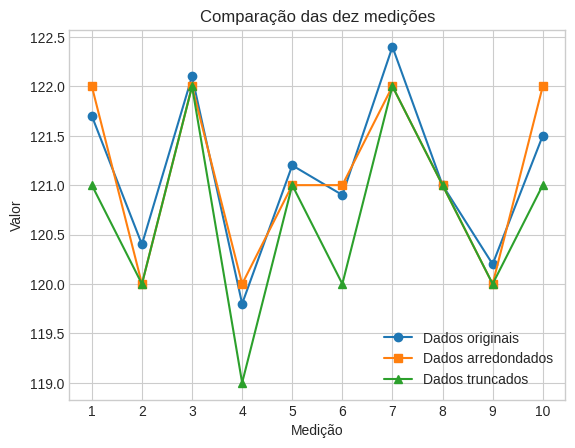

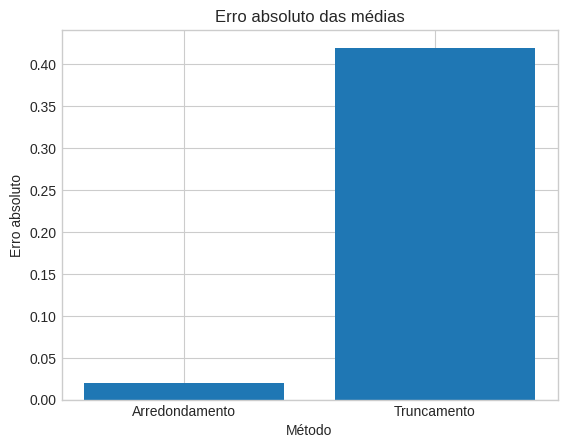

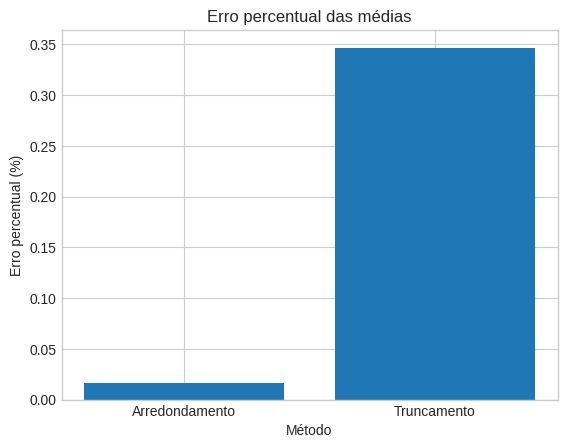

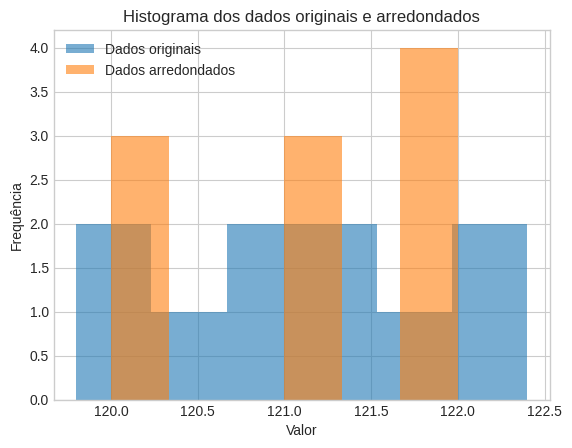

In [9]:
# ==========================================================
# DADOS ORIGINAIS
# ==========================================================

p = [
    121.7, 120.4, 122.1, 119.8, 121.2,
    120.9, 122.4, 121.0, 120.2, 121.5
]


# ==========================================================
# MÉDIA DOS DADOS ORIGINAIS
# ==========================================================

media = sum(p) / len(p)

print(f"Média dos dados originais: {media}")

Valorderef = media

print(f"Dados originais: {p}")


# ==========================================================
# ARREDONDAMENTO E TRUNCAMENTO
# ==========================================================

# Dados arredondados para o inteiro mais próximo
a = [round(x, 0) for x in p]

# Dados truncados para números inteiros
t = [truncar(x, 0) for x in p]

print(f"Dados arredondados: {a}")
print(f"Dados truncados: {t}")


# ==========================================================
# MÉDIAS
# ==========================================================

mediaa = sum(a) / len(a)
mediat = sum(t) / len(t)

print(f"Média dos dados arredondados: {mediaa}")
print(f"Média dos dados truncados: {mediat}")


# ==========================================================
# MÍNIMOS E MÁXIMOS
# ==========================================================

minp = min(p)
maxp = max(p)

print(f"Mínimo dos dados originais: {minp}")
print(f"Máximo dos dados originais: {maxp}")


mina = min(a)
maxa = max(a)

print(f"Mínimo dos dados arredondados: {mina}")
print(f"Máximo dos dados arredondados: {maxa}")


mint = min(t)
maxt = max(t)

print(f"Mínimo dos dados truncados: {mint}")
print(f"Máximo dos dados truncados: {maxt}")


# ==========================================================
# DESVIO PADRÃO
# ==========================================================

desvp = statistics.pstdev(p)
desva = statistics.pstdev(a)
desvt = statistics.pstdev(t)

print(f"Desvio padrão dos dados originais: {desvp}")
print(f"Desvio padrão dos dados arredondados: {desva}")
print(f"Desvio padrão dos dados truncados: {desvt}")


# ==========================================================
# ERROS DAS MÉDIAS
# ==========================================================

# Erro da média arredondada
Ea_a, Er_a, Eperc_a = calcular_erros(
    Valorderef,
    mediaa
)

# Erro da média truncada
Ea_t, Er_t, Eperc_t = calcular_erros(
    Valorderef,
    mediat
)


print("\nERROS DA MÉDIA ARREDONDADA")

print(f"Erro absoluto:   {Ea_a:.10f}")
print(f"Erro relativo:   {Er_a:.6e}")
print(f"Erro percentual: {Eperc_a:.6f}%")


print("\nERROS DA MÉDIA TRUNCADA")

print(f"Erro absoluto:   {Ea_t:.10f}")
print(f"Erro relativo:   {Er_t:.6e}")
print(f"Erro percentual: {Eperc_t:.6f}%")


# ==========================================================
# 1. GRÁFICO DAS DEZ MEDIÇÕES
# MOSTRANDO AS TRÊS SÉRIES
# ==========================================================

medicoes = range(1, len(p) + 1)

plt.figure()

plt.plot(
    medicoes,
    p,
    marker="o",
    label="Dados originais"
)

plt.plot(
    medicoes,
    a,
    marker="s",
    label="Dados arredondados"
)

plt.plot(
    medicoes,
    t,
    marker="^",
    label="Dados truncados"
)

plt.xlabel("Medição")
plt.ylabel("Valor")
plt.title("Comparação das dez medições")

plt.xticks(medicoes)

plt.grid(True)

plt.legend()

plt.show()


# ==========================================================
# 2. GRÁFICO DE BARRAS DOS ERROS ABSOLUTOS DAS MÉDIAS
# ==========================================================

metodos = [
    "Arredondamento",
    "Truncamento"
]

erros_absolutos = [
    Ea_a,
    Ea_t
]


plt.figure()

plt.bar(
    metodos,
    erros_absolutos
)

plt.xlabel("Método")
plt.ylabel("Erro absoluto")
plt.title("Erro absoluto das médias")

plt.show()


# ==========================================================
# 3. GRÁFICO DE BARRAS DOS ERROS PERCENTUAIS DAS MÉDIAS
# ==========================================================

erros_percentuais = [
    Eperc_a,
    Eperc_t
]


plt.figure()

plt.bar(
    metodos,
    erros_percentuais
)

plt.xlabel("Método")
plt.ylabel("Erro percentual (%)")
plt.title("Erro percentual das médias")

plt.show()


# ==========================================================
# 4. HISTOGRAMA DOS DADOS ORIGINAIS
# E DOS DADOS INTEIROS ARREDONDADOS
# ==========================================================

plt.figure()

plt.hist(
    p,
    bins=6,
    alpha=0.6,
    label="Dados originais"
)

plt.hist(
    a,
    bins=6,
    alpha=0.6,
    label="Dados arredondados"
)

plt.xlabel("Valor")
plt.ylabel("Frequência")
plt.title(
    "Histograma dos dados originais e arredondados"
)

plt.legend()

plt.show()


**Explique se a representação inteira é suficiente para preservar a média e a variabilidade desta pequena amostra. Não faça interpretação médica dos valores.**
Sim, pois não gerou grandes variações no desvio padrão ou grandes valores de erro quando comparada a média dos valores originais.

In [18]:
def Q(r,L,u,deltap):
  Q=(math.pi*(r**4)*deltap)/(8*u*L)
  return Q
r=0.8*(10**-3)
rmm=0.8
L=0.2 # Corrected: used period for decimal, not comma
u=3.5*(10**-3)
deltap=1200
print(f"Q original: {Q(r,L,u,deltap)}") # Corrected: used f-string for printing
Qo=Q(r,L,u,deltap)
rr=round(rmm,1)*(10**-3)
rt=truncar(rmm,1)*(10**-3) # Corrected: used 'truncar' instead of 'truncado'
print(f"Q r arredondado: {Q(rr,L,u,deltap)}")
Qrr=Q(rr,L,u,deltap)
print(f"Q r truncado: {Q(rt,L,u,deltap)}")
Qrt=Q(rt,L,u,deltap)
ur=round(u,3)
ut=truncar(u,3)
print(f"Q u arredondado: {Q(r,L,ur,deltap)}")
Qur=Q(r,L,ur,deltap)
print(f"Q u truncado: {Q(r,L,ut,deltap)}")
Qut=Q(r,L,ut,deltap)
deltapcentenas=deltap/100
deltapr=round(deltapcentenas,1)*100
deltapt=truncar(deltapcentenas,1)*100
print(f"Q delta arredondado: {Q(r,L,u,deltapr)}")
Qpr=Q(r,L,u,deltapr)
print(f"Q delta truncado: {Q(r,L,u,deltapt)}")
Qpt=Q(r,L,u,deltapt)
print(f"Q arredondado: {Q(rr,L,ur,deltapr)}")
Qr=Q(rr,L,ur,deltapr)
Qt=Q(rt,L,ut,deltapt)
print(f"Q truncado: {Q(rt,L,ut,deltapt)}")
EaQr=calcular_erros(Qo,Qr)
EaQt=calcular_erros(Qo,Qt)
print(f"Ea Q arredondado: {EaQr}")
print(f"Ea Q truncado: {EaQt}")
EaQrr=calcular_erros(Qo,Qrr)
EaQrt=calcular_erros(Qo,Qrt)
EaQur=calcular_erros(Qo,Qur)
EaQut=calcular_erros(Qo,Qut)
EaQpr=calcular_erros(Qo,Qpr)
EaQpt=calcular_erros(Qo,Qpt)
print(f"Ea Q r arredondado: {EaQrr}")
print(f"Ea Q r truncado: {EaQrt}")
print(f"Ea Q u arredondado: {EaQur}")
print(f"Ea Q u truncado: {EaQut}")
print(f"Ea Q delta arredondado: {EaQpr}")
print(f"Ea Q delta truncado: {EaQpt}")

#

Q original: 2.757420751950813e-07
Q r arredondado: 2.757420751950813e-07
Q r truncado: 2.757420751950813e-07
Q u arredondado: 2.4127431579569616e-07
Q u truncado: 3.2169908772759484e-07
Q delta arredondado: 2.757420751950813e-07
Q delta truncado: 2.757420751950813e-07
Q arredondado: 2.4127431579569616e-07
Q truncado: 3.2169908772759484e-07
Ea Q arredondado: (3.446775939938513e-08, 0.12499999999999988, 12.499999999999988)
Ea Q truncado: (4.5957012532513556e-08, 0.16666666666666669, 16.666666666666668)
Ea Q r arredondado: (0.0, 0.0, 0.0)
Ea Q r truncado: (0.0, 0.0, 0.0)
Ea Q u arredondado: (3.446775939938513e-08, 0.12499999999999988, 12.499999999999988)
Ea Q u truncado: (4.5957012532513556e-08, 0.16666666666666669, 16.666666666666668)
Ea Q delta arredondado: (0.0, 0.0, 0.0)
Ea Q delta truncado: (0.0, 0.0, 0.0)
